# Colecity · Essa reclamação vai ser resolvida?

**Pergunta de Machine Learning:** a partir do tipo de reclamação, do lugar e da data,
conseguimos prever se uma reclamação de **transporte** feita ao SP156 será **resolvida (Finalizada)** ou não?

**Por que isso importa para o Colecity:** se o modelo mostra que certas reclamações quase nunca
são resolvidas quando feitas sozinhas, essas são as que mais precisam virar um **abaixo-assinado coletivo**.

**Dados:** reais e públicos, do Portal de Dados Abertos da Prefeitura de São Paulo (Dados do SP156).

**Modelo:** Random Forest (classificação).

## 1. Importar as bibliotecas

In [ ]:
import glob
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 2. Carregar os dados

In [ ]:
# Lê a primeira aba ("Solicitações") do arquivo do SP156
df = pd.read_excel('arquivo-final-2-trim-26.xlsx', sheet_name=0)

print('Total de linhas:', len(df))
df.head()

Total de linhas: 463686


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,2026-04-01,2026-04-02,CRM,Ouvidoria Geral do Município,Ouvidoria Geral do Município,Reclamação Anônima (Uso exclusivo da Ouvidoria),Finalizada,OGM - SMS,Rua Doutor Siqueira Campos,172.0,01509020,-23.563722,-46.637294,SE,LIBERDADE
1,2026-04-01,2026-04-02,PORTAL,Rua e bairro,Drenagem de água de chuva,Reformar galerias de águas de chuvas (pluviais),Finalizada,INTEGRAÇÃO-SMGI/SGZ,Rua dos Pinheiros,14.0,04966050,-23.726967,-46.780983,M BOI MIRIM,JARDIM ANGELA
2,2026-04-01,NaT,CRM,Rua e bairro,"Calçadas, guias e postes","Guias, sarjetas e sarjetões - solicitar manute...",Aberto,INTEGRAÇÃO-SMGI/SGZ,Avenida Líder,1732.0,08280005,-23.556329,-46.478276,ITAQUERA,CIDADE LIDER
3,2026-04-01,2026-04-02,CRM,Animais,Animais que transmitem doenças ou risco à saúde,Abelhas e Vespas - Solicitar vistoria em ninhos,Finalizada,SMS-COVISA-UVIS-Butantã,Rua Doutor Francisco Pati,345.0,05352070,-23.557470,-46.759012,BUTANTA,RIO PEQUENO
4,2026-04-01,2026-04-02,PORTAL,"Cultura, esporte e lazer",Centros esportivos,Centros Esportivos - Solicitar Carteirinha,Finalizada,SEME-CE-Vila-Maria,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Padronizar os nomes das colunas


In [ ]:
def limpar_nome(nome):
    nome = unicodedata.normalize('NFKD', str(nome)).encode('ascii', 'ignore').decode()
    return nome.strip().lower().replace(' ', '_')

df.columns = [limpar_nome(c) for c in df.columns]
print(list(df.columns))

['data_de_abertura', 'data_de_finalizacao', 'meio_de_comunicacao', 'tema', 'assunto', 'servico', 'status', 'orgao', 'logradouro', 'numero', 'cep', 'latitude', 'longitude', 'prefeitura_operacional', 'distrito']


In [ ]:
def achar_coluna(palavra):
    for c in df.columns:
        if palavra in c:
            return c
    raise KeyError(f'Nenhuma coluna com "{palavra}". Confira a lista de colunas acima.')

df = df.rename(columns={
    achar_coluna('abertura'): 'data',
    achar_coluna('status'): 'status',
    achar_coluna('tema'): 'tema',
    achar_coluna('assunto'): 'assunto',
    achar_coluna('servico'): 'servico',
    achar_coluna('prefeitura'): 'subprefeitura',  # no arquivo se chama "Prefeitura Operacional"
    achar_coluna('distrito'): 'distrito',
    achar_coluna('meio'): 'canal',
})
df = df[['data', 'status', 'tema', 'assunto', 'servico', 'subprefeitura', 'distrito', 'canal']]
df.head()

,data,status,tema,assunto,servico,subprefeitura,distrito,canal
0,2026-04-01,Finalizada,Ouvidoria Geral do Município,Ouvidoria Geral do Município,Reclamação Anônima (Uso exclusivo da Ouvidoria),SE,LIBERDADE,CRM
1,2026-04-01,Finalizada,Rua e bairro,Drenagem de água de chuva,Reformar galerias de águas de chuvas (pluviais),M BOI MIRIM,JARDIM ANGELA,PORTAL
2,2026-04-01,Aberto,Rua e bairro,"Calçadas, guias e postes","Guias, sarjetas e sarjetões - solicitar manute...",ITAQUERA,CIDADE LIDER,CRM
3,2026-04-01,Finalizada,Animais,Animais que transmitem doenças ou risco à saúde,Abelhas e Vespas - Solicitar vistoria em ninhos,BUTANTA,RIO PEQUENO,CRM
4,2026-04-01,Finalizada,"Cultura, esporte e lazer",Centros esportivos,Centros Esportivos - Solicitar Carteirinha,NaN,NaN,PORTAL


In [ ]:
df['status'].unique()

array(['Finalizada', 'Aberto', 'Em Andamento', 'Cancelada'], dtype=object)

## 4. Preparar os dados

1. **Filtrar** só as reclamações do tema *Trânsito e Transporte* (o módulo do MVP do Colecity).
2. **Criar o alvo** (o que queremos prever):
   - `1` = **Finalizada** (resolvida)
   - `0` = **Aberto**, **Em Andamento** ou **Indeferido** (não resolvida)
   - **Cancelada** é removida, porque foi o próprio cidadão que desistiu.

   Os dados foram extraídos pela Prefeitura em outubro de 2026. Uma reclamação de abril a junho
   que ainda está "Aberto" está parada há mais de 3 meses, por isso conta como não resolvida.
3. **Limpar:** removemos linhas sem data ou sem assunto. Quando falta o local
   (subprefeitura ou distrito), preenchemos com "NAO INFORMADO" em vez de jogar a linha fora,
   porque isso acontece em mais da metade das reclamações.

In [ ]:
# 1. Só transporte
df = df[df['tema'].str.contains('transporte', case=False, na=False)]

# 2. Alvo
df['status'] = df['status'].str.strip().str.lower()
df = df[~df['status'].str.contains('cancel', na=False)]
df['resolvida'] = df['status'].str.contains('finaliz', na=False).astype(int)

# 3. Datas e linhas vazias
df['data'] = pd.to_datetime(df['data'], dayfirst=True, errors='coerce')
df = df.dropna(subset=['data', 'assunto'])
for coluna in ['subprefeitura', 'distrito', 'servico', 'canal']:
    df[coluna] = df[coluna].fillna('NAO INFORMADO')

print('Linhas depois da limpeza:', len(df))
print(df['status'].value_counts())

Linhas depois da limpeza: 87238
status
finalizada      74276
aberto          12890
em andamento       72
Name: count, dtype: int64


## 5. Criar variáveis a partir da data

O modelo não entende uma data inteira, então separei em partes simples:
dia do mês e dia da semana (0 = segunda). O arquivo não traz a hora da reclamação.

In [ ]:
df['dia_mes'] = df['data'].dt.day
df['dia_semana'] = df['data'].dt.dayofweek
df[['data', 'dia_mes', 'dia_semana']].head()

,data,dia_mes,dia_semana
80,2026-04-01,1,2
88,2026-04-01,1,2
90,2026-04-01,1,2
99,2026-04-01,1,2
103,2026-04-01,1,2


In [ ]:
df.head()

,data,status,tema,assunto,servico,subprefeitura,distrito,canal,resolvida,dia_mes,dia_semana
80,2026-04-01,finalizada,Trânsito e Transporte,Ônibus e ponto de ônibus,Ônibus - Manutenção do veículo em geral,VILA PRUDENTE,SAO LUCAS,PORTAL,1,1,2
88,2026-04-01,finalizada,Trânsito e Transporte,Ônibus e ponto de ônibus,Ônibus - Manutenção do veículo em geral,VILA MARIANA,VILA MARIANA,PORTAL,1,1,2
90,2026-04-01,finalizada,Trânsito e Transporte,Ônibus - Linhas e itinerários,Ônibus - Reclamar de intervalo excessivo da linha,CAPELA DO SOCORRO,GRAJAU,CRM,1,1,2
99,2026-04-01,aberto,Trânsito e Transporte,Veículos abandonados,Solicitar remoção de veículo/carcaça abandonad...,BUTANTA,VILA SONIA,PORTAL,0,1,2
103,2026-04-01,finalizada,Trânsito e Transporte,Ônibus e ponto de ônibus,Ônibus - Manutenção do veículo em geral,SE,SE,PORTAL,1,1,2


## 6. Olhar os dados antes de treinar

Taxa geral de resolução: 85.1%


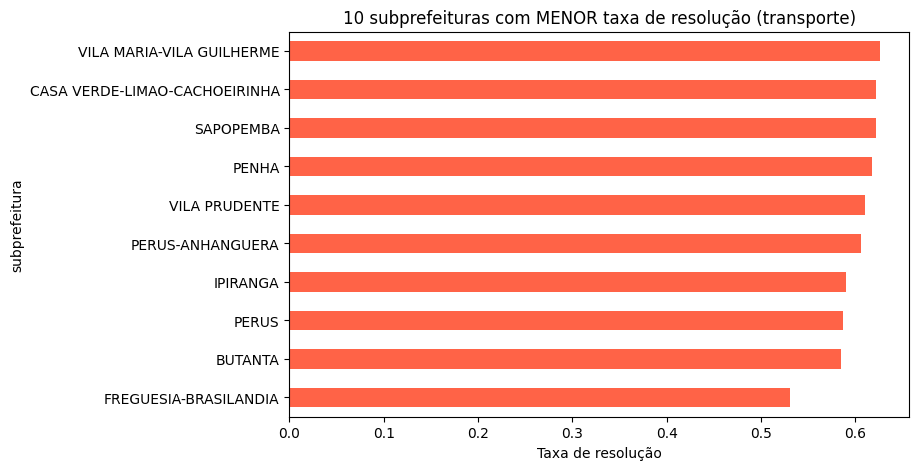

In [ ]:
print(f"Taxa geral de resolução: {df['resolvida'].mean():.1%}")

com_local = df[df['subprefeitura'] != 'NAO INFORMADO']
taxa_sub = com_local.groupby('subprefeitura')['resolvida'].mean().sort_values()
taxa_sub.head(10).plot(kind='barh', figsize=(8, 5), color='tomato')
plt.title('10 subprefeituras com MENOR taxa de resolução (transporte)')
plt.xlabel('Taxa de resolução')
plt.show()

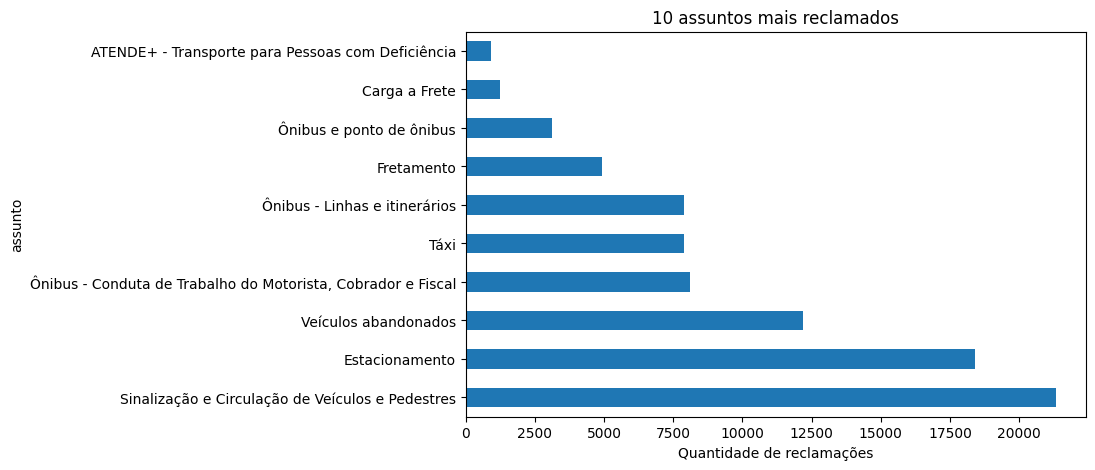

In [ ]:
df['assunto'].value_counts().head(10).plot(kind='barh', figsize=(8, 5))
plt.title('10 assuntos mais reclamados')
plt.xlabel('Quantidade de reclamações')
plt.show()

## 7. Dividir em treino e teste

A divisão é **por tempo** e não aleatória: treinamos com o **passado** e testamos no **futuro**,
como aconteceria de verdade no app.

- **Treino:** todos os meses, menos o último (abril e maio de 2026)
- **Teste:** o último mês (junho de 2026)

Para o treino não demorar demais, usamos no máximo 100 mil linhas de treino.

In [ ]:
df = df.sort_values('data')

# O último mês dos dados vira o teste
inicio_teste = df['data'].max().to_period('M').to_timestamp()
treino = df[df['data'] < inicio_teste]
teste = df[df['data'] >= inicio_teste]
print('Teste começa em:', inicio_teste.date())

if len(treino) > 100000:
    treino = treino.sample(100000, random_state=42).sort_values('data')

variaveis = ['assunto', 'servico', 'subprefeitura', 'distrito', 'canal', 'dia_mes', 'dia_semana']

X_treino, y_treino = treino[variaveis], treino['resolvida']
X_teste, y_teste = teste[variaveis], teste['resolvida']

print('Treino:', len(X_treino), 'linhas | Teste:', len(X_teste), 'linhas')

Teste começa em: 2026-06-01
Treino: 57957 linhas | Teste: 29281 linhas


## 8. Montar o modelo

- **OneHotEncoder:** transforma texto (ex.: nome da subprefeitura) em colunas de 0 e 1, que o modelo entende.
  Categorias muito raras (menos de 50 aparições) são agrupadas em "outros".
- **RandomForestClassifier:** várias árvores de decisão que "votam" na resposta.
  `class_weight='balanced'` faz o modelo dar a mesma atenção às duas classes, mesmo que uma seja mais rara.

In [ ]:
texto = ['assunto', 'servico', 'subprefeitura', 'distrito', 'canal']
numeros = ['dia_mes', 'dia_semana']

preparacao = ColumnTransformer([
    ('texto', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50), texto),
    ('numeros', 'passthrough', numeros),
])

modelo = Pipeline([
    ('preparacao', preparacao),
    ('floresta', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)),
])

## 9. Testar diferentes hiperparâmetros

Treinei **3 modelos** e, para cada um, testamos **12 combinações de 3 hiperparâmetros**:

| Modelo | Como funciona | Hiperparâmetros testados |
|---|---|---|
| **Random Forest** | várias árvores independentes que "votam" na resposta | `n_estimators` (50, 100) · `max_depth` (5, 10, 20) · `min_samples_leaf` (1, 20) |
| **XGBoost** | árvores feitas uma depois da outra, cada uma corrigindo os erros da anterior | `n_estimators` (100, 200) · `max_depth` (3, 6, 10) · `learning_rate` (0,05, 0,3) |
| **LightGBM** | parecido com o XGBoost, mas cresce as árvores de outro jeito e costuma ser mais rápido | `n_estimators` (100, 200) · `num_leaves` (15, 31, 63) · `learning_rate` (0,05, 0,3) |

**O que cada hiperparâmetro significa:**
- `n_estimators`: quantas árvores o modelo usa.
- `max_depth`: profundidade máxima de cada árvore (quantas perguntas seguidas ela pode fazer).
- `min_samples_leaf`: mínimo de exemplos em cada "folha" da árvore. Valores maiores evitam que o modelo decore casos raros.
- `learning_rate`: o tamanho da correção que cada nova árvore faz. Valores menores aprendem mais devagar, mas com mais cuidado.
- `num_leaves`: quantas "folhas" (respostas finais) cada árvore pode ter.

**As regras são iguais para os três, para a comparação ser justa:**
- a **validação cruzada** é feita **só nos dados de treino**, com `TimeSeriesSplit` (cada rodada treina no passado e valida no período seguinte);
- a melhor combinação de cada modelo é escolhida pelo **F1 macro**, a média do F1 da classe "resolvida" e da classe "não resolvida". Assim nenhum modelo consegue "trapacear" chutando sempre a mesma resposta;
- as reclamações não resolvidas, que são mais raras, recebem peso maior (`class_weight='balanced'` no Random Forest e no LightGBM, `scale_pos_weight` no XGBoost).

In [ ]:
parametros = {
    'floresta__n_estimators': [50, 100],
    'floresta__max_depth': [5, 10, 20],
    'floresta__min_samples_leaf': [1, 20],
}

busca = GridSearchCV(
    modelo,
    parametros,
    cv=TimeSeriesSplit(n_splits=3),
    scoring='f1_macro',
    return_train_score=True,
    n_jobs=-1,
)
busca.fit(X_treino, y_treino)

print('Melhor combinação:', busca.best_params_)
print(f'F1 macro médio na validação: {busca.best_score_:.3f}')

Melhor combinação: {'floresta__max_depth': 20, 'floresta__min_samples_leaf': 1, 'floresta__n_estimators': 100}
F1 macro médio na validação: 0.898


In [ ]:
resultados = pd.DataFrame(busca.cv_results_)
tabela = resultados[['param_floresta__n_estimators', 'param_floresta__max_depth',
                     'param_floresta__min_samples_leaf', 'mean_train_score', 'mean_test_score']]
tabela.columns = ['n_estimators', 'max_depth', 'min_samples_leaf', 'F1 treino', 'F1 validação']
tabela = tabela.sort_values('F1 validação', ascending=False).round(3)
tabela

,n_estimators,max_depth,min_samples_leaf,F1 treino,F1 validação
9,100,20,1,0.932,0.898
8,50,20,1,0.931,0.895
4,50,10,1,0.904,0.893
5,100,10,1,0.899,0.890
10,50,20,20,0.895,0.887
11,100,20,20,0.895,0.887
6,50,10,20,0.890,0.885
7,100,10,20,0.887,0.882
1,100,5,1,0.879,0.874
0,50,5,1,0.879,0.874


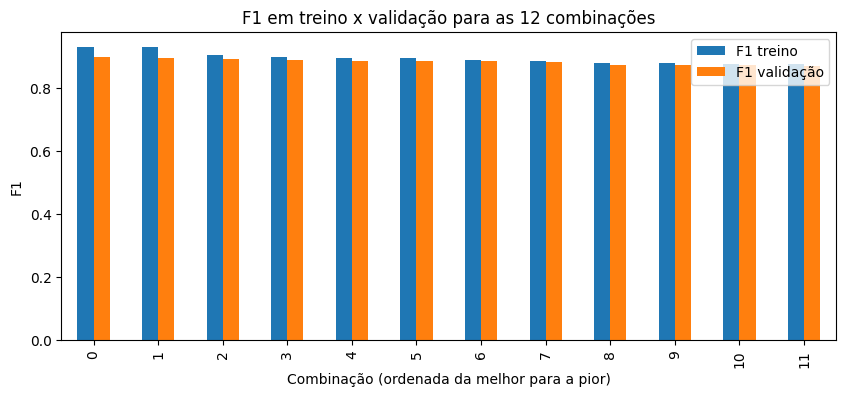

In [ ]:
tabela_grafico = tabela.reset_index(drop=True)
tabela_grafico[['F1 treino', 'F1 validação']].plot(kind='bar', figsize=(10, 4))
plt.title('F1 em treino x validação para as 12 combinações')
plt.xlabel('Combinação (ordenada da melhor para a pior)')
plt.ylabel('F1')
plt.show()

In [ ]:
peso = (y_treino == 0).sum() / (y_treino == 1).sum()

outros_modelos = {
    'XGBoost': (
        Pipeline([('preparacao', preparacao),
                  ('modelo', XGBClassifier(scale_pos_weight=peso, random_state=42, n_jobs=-1))]),
        {'modelo__n_estimators': [100, 200],
         'modelo__max_depth': [3, 6, 10],
         'modelo__learning_rate': [0.05, 0.3]},
    ),
    'LightGBM': (
        Pipeline([('preparacao', preparacao),
                  ('modelo', LGBMClassifier(class_weight='balanced', random_state=42, n_jobs=1, verbose=-1))]),
        {'modelo__n_estimators': [100, 200],
         'modelo__num_leaves': [15, 31, 63],
         'modelo__learning_rate': [0.05, 0.3]},
    ),
}

buscas = {'Random Forest': busca}  # o Random Forest já foi treinado
for nome, (pipeline, parametros) in outros_modelos.items():
    print('Treinando', nome, '...')
    buscas[nome] = GridSearchCV(pipeline, parametros, cv=TimeSeriesSplit(n_splits=3),
                                scoring='f1_macro', n_jobs=-1).fit(X_treino, y_treino)
    print('  melhor combinação:', buscas[nome].best_params_)

Treinando XGBoost ...
  melhor combinação: {'modelo__learning_rate': 0.05, 'modelo__max_depth': 10, 'modelo__n_estimators': 200}
Treinando LightGBM ...
  melhor combinação: {'modelo__learning_rate': 0.05, 'modelo__n_estimators': 100, 'modelo__num_leaves': 63}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,F1 validação,F1 treino,F1 teste,Diferença treino - teste
Random Forest,0.898,0.928,0.893,0.035
XGBoost,0.890,0.897,0.894,0.003
LightGBM,0.888,0.891,0.895,-0.004


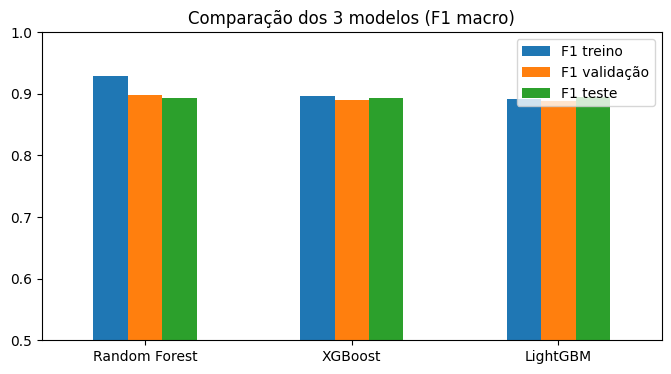

In [ ]:
comparacao_modelos = pd.DataFrame({
    nome: {
        'F1 validação': b.best_score_,
        'F1 treino': f1_score(y_treino, b.best_estimator_.predict(X_treino), average='macro'),
        'F1 teste': f1_score(y_teste, b.best_estimator_.predict(X_teste), average='macro'),
    }
    for nome, b in buscas.items()
}).T
comparacao_modelos['Diferença treino - teste'] = comparacao_modelos['F1 treino'] - comparacao_modelos['F1 teste']
display(comparacao_modelos.round(3))

comparacao_modelos[['F1 treino', 'F1 validação', 'F1 teste']].plot(kind='bar', figsize=(8, 4))
plt.title('Comparação dos 3 modelos (F1 macro)')
plt.ylim(0.5, 1)
plt.xticks(rotation=0)
plt.show()

### Por que escolher o Random Forest?

Repeti o mesmo processo com mais dois modelos (XGBoost e LightGBM): mesma divisão treino/teste, mesma validação cruzada por tempo, mesma métrica (F1 macro) e 12 combinações de hiperparâmetros para cada um.

| Modelo | F1 validação | F1 treino | F1 teste | Diferença treino − teste |
|---|---|---|---|---|
| **Random Forest** | **0,898** | 0,928 | 0,893 | 0,035 |
| XGBoost | 0,890 | 0,897 | 0,894 | 0,003 |
| LightGBM | 0,888 | 0,891 | 0,895 | −0,004 |

- **O modelo é escolhido pela validação, não pelo teste.** O teste é a "prova final" e não pode ser usado para escolher. Na validação, o **Random Forest teve o maior F1 (0,898)**, à frente do XGBoost (0,890) e do LightGBM (0,888).
- **No teste os três ficaram praticamente empatados** (entre 0,893 e 0,895). Uma diferença de 0,002 é desprezível, o que mostra que o Random Forest se sai tão bem quanto os outros em dados novos.
- **O Random Forest tem um pouco mais de overfitting** (diferença de 0,035 entre treino e teste, contra quase zero nos outros dois). Ainda assim, a diferença é pequena, bem abaixo de 0,10, e não prejudicou o resultado no teste.
- **Vantagens práticas:** o Random Forest já vem no scikit-learn, sem instalar bibliotecas extras, e mostra de forma direta **quais variáveis mais pesam** na decisão (seção 11). Isso facilita explicar o resultado para o cidadão.

## 10. Resultado final: treino × teste

In [ ]:
melhor = busca.best_estimator_

def metricas(y_real, y_previsto):
    return {
        'Acurácia': accuracy_score(y_real, y_previsto),
        'Precisão': precision_score(y_real, y_previsto, average='macro'),
        'Recall': recall_score(y_real, y_previsto, average='macro'),
        'F1': f1_score(y_real, y_previsto, average='macro'),
    }

comparacao = pd.DataFrame({
    'Treino': metricas(y_treino, melhor.predict(X_treino)),
    'Teste': metricas(y_teste, melhor.predict(X_teste)),
}).round(3)
comparacao

,Treino,Teste
Acurácia,0.964,0.940
Precisão,0.903,0.906
Recall,0.959,0.881
F1,0.928,0.893


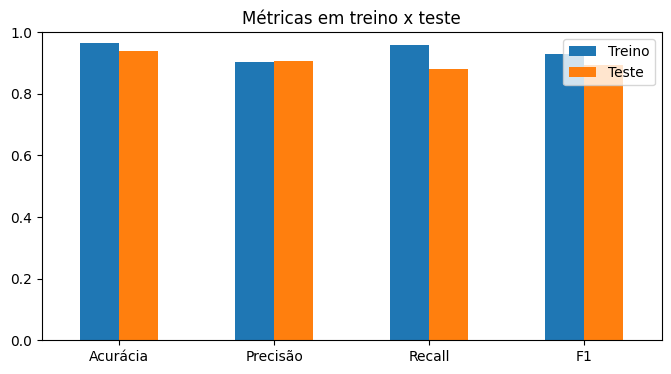

In [ ]:
comparacao.plot(kind='bar', figsize=(8, 4))
plt.title('Métricas em treino x teste')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

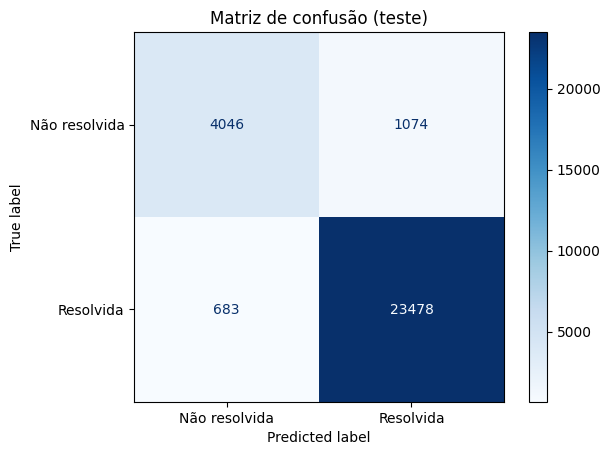

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    melhor, X_teste, y_teste,
    display_labels=['Não resolvida', 'Resolvida'], cmap='Blues')
plt.title('Matriz de confusão (teste)')
plt.show()

**Overfitting:** comparamos as métricas de treino e de teste. Se o treino for muito melhor que o teste (diferença acima de ~0,10), o modelo "decorou" o passado e não funciona bem com dados novos.
No nosso caso, o F1 caiu de 0,928 (treino) para 0,893 (teste), uma diferença de só 0,035. Ou seja, há pouco overfitting: o modelo aprendeu padrões que se repetem no mês seguinte.

## 11. O que mais pesa na previsão?

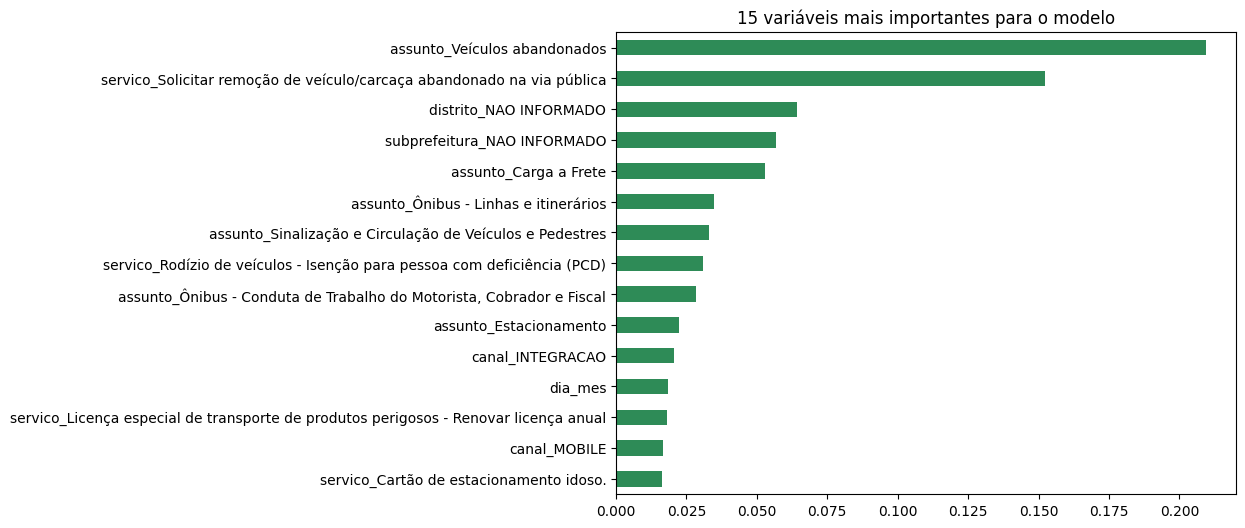

In [ ]:
nomes = melhor.named_steps['preparacao'].get_feature_names_out()
importancias = melhor.named_steps['floresta'].feature_importances_

top = pd.Series(importancias, index=nomes).sort_values().tail(15)
top.index = [n.replace('texto__', '').replace('numeros__', '') for n in top.index]
top.plot(kind='barh', figsize=(8, 6), color='seagreen')
plt.title('15 variáveis mais importantes para o modelo')
plt.show()

## 12. Leitura para o cidadão

Usamos o modelo para calcular, em cada subprefeitura, a **chance média de uma reclamação de
transporte ser resolvida** no período de teste. As que têm menor chance são onde o Colecity
deve priorizar o **abaixo-assinado coletivo**.

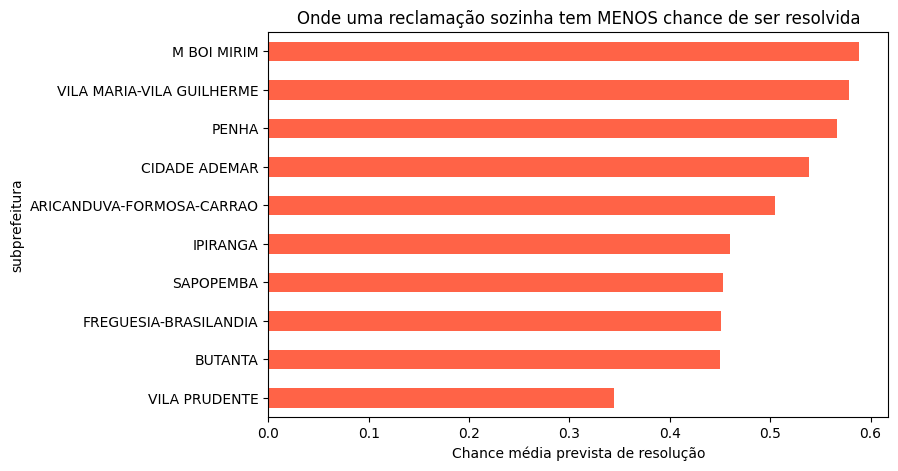

,chance_resolver
subprefeitura,
VILA PRUDENTE,0.344
BUTANTA,0.450
FREGUESIA-BRASILANDIA,0.451
SAPOPEMBA,0.453
IPIRANGA,0.460
ARICANDUVA-FORMOSA-CARRAO,0.505
CIDADE ADEMAR,0.538
PENHA,0.567
VILA MARIA-VILA GUILHERME,0.579


In [ ]:
teste = teste.copy()
teste['chance_resolver'] = melhor.predict_proba(X_teste)[:, 1]

teste_com_local = teste[teste['subprefeitura'] != 'NAO INFORMADO']
ranking = teste_com_local.groupby('subprefeitura')['chance_resolver'].mean().sort_values()
ranking.head(10).plot(kind='barh', figsize=(8, 5), color='tomato')
plt.title('Onde uma reclamação sozinha tem MENOS chance de ser resolvida')
plt.xlabel('Chance média prevista de resolução')
plt.show()

ranking.head(10).round(3)

## 13. Conclusão

- O modelo teve **F1 macro de 0,893 no teste** (junho de 2026) e acurácia de **94,0%**.
- No treino o F1 foi **0,928**. A diferença para o teste é de só **0,035**, então há **pouco overfitting**: o modelo aprendeu padrões que se repetem no mês seguinte.
- A melhor combinação foi `n_estimators=100`, `max_depth=20` e `min_samples_leaf=1`. Árvores mais rasas (`max_depth=5`) erraram mais (F1 de validação de 0,874).
- O que mais pesa na previsão é o **tipo de reclamação**. *Veículos abandonados* tem a menor taxa de resolução: cerca de **22%**, contra mais de 90% na maioria dos outros assuntos.
- Nas subprefeituras **Vila Prudente, Butantã, Sapopemba, Freguesia/Brasilândia e Ipiranga**, uma reclamação de transporte feita sozinha tem a **menor chance prevista de ser resolvida**. As taxas reais de junho confirmam isso: Butantã resolveu 40% e Vila Prudente 44%.

**Limitação:** "Finalizada" significa que a Prefeitura **fechou o protocolo**, não necessariamente que o problema acabou. Reclamações sobre ônibus, por exemplo, aparecem quase 100% como finalizadas. Esse é justamente um ponto que o Colecity resolve, ao deixar o próprio cidadão confirmar se o problema foi resolvido.

**Para o cidadão:** no Colecity, quando alguém dessas regiões registrar um problema como um veículo abandonado, o app mostra que reclamar sozinho dificilmente resolve e convida a pessoa a entrar no abaixo-assinado. Assim, o relato individual vira evidência coletiva.
